In [1]:
import pandas as pd

In [2]:
df= pd.read_csv(r"C:\Users\singh\OneDrive\Desktop\Real-Estate-Price-Prediction\data\processed\house_prices_cleaned.csv")
df.shape
df.head()

,area_type,availability,location,size,total_sqft,bath,balcony,price,bhk,total_sqft_num
0,Super built-up Area,19-Dec,Electronic City Phase II,2 BHK,1056,2.0,1.0,39.07,2.0,1056.0
1,Plot Area,Ready To Move,Chikka Tirupathi,4 Bedroom,2600,5.0,3.0,120.00,4.0,2600.0
2,Built-up Area,Ready To Move,Uttarahalli,3 BHK,1440,2.0,3.0,62.00,3.0,1440.0
3,Super built-up Area,Ready To Move,Lingadheeranahalli,3 BHK,1521,3.0,1.0,95.00,3.0,1521.0
4,Super built-up Area,Ready To Move,Kothanur,2 BHK,1200,2.0,1.0,51.00,2.0,1200.0


In [3]:
df["bhk"]=df["size"].str.extract(r"(\d+)").astype(float)

In [4]:
df["sqft_per_bhk"]=(
    df["total_sqft_num"] / df["bhk"]
)

In [5]:
df_model=df[
    df["sqft_per_bhk"]>=300
].copy()

df_model["area_type"] = df_model["area_type"].str.strip()

df_model= df_model[
    df_model["area_type"] != "Plot  Area"
].copy()

df_model=df_model[
    df_model["total_sqft_num"] <=20000
].copy()


In [6]:
print("Model-ready rows:", len(df_model))
print("Plot Area:", (df_model["area_type"] == "Plot Area").sum())
print("Maximum area:", df_model["total_sqft_num"].max())

Model-ready rows: 10674
Plot Area: 0
Maximum area: 16335.0


In [7]:
df_model.to_csv(
    r"C:\Users\singh\OneDrive\Desktop\Real-Estate-Price-Prediction\data\processed\house_prices_model_ready.csv",
    index=False
)
print("File successfully saved")

File successfully saved


In [8]:
features=[
    "area_type",
    "location",
    "bhk",
    "bath",
    "total_sqft_num",
    "balcony"
]

X=df_model[features]
y=df_model["price"]

print("X shape", X.shape)
print("y shape",y.shape)

X shape (10674, 6)
y shape (10674,)


In [9]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)
print("Training data",X_train.shape)
print("Testing Data",y_train.shape)

Training data (8539, 6)
Testing Data (8539,)


In [10]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

categorical_features=[
    "area_type",
    "location"
]
numerical_features=[
    "bhk",
    "bath",
    "total_sqft_num",
    "balcony"
]

preprocessor = ColumnTransformer(
    transformers =[
        (
            "categorical",
            OneHotEncoder(
                handle_unknown="ignore"
            ),
            categorical_features
        ),
        (
            "numerical",
            "passthrough",
            numerical_features
        )
    ]
)

In [11]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression

linear_model=Pipeline(
    steps=[
        ("preprocessor",preprocessor),
        ("model",LinearRegression())
    ]
)

In [12]:
linear_model.fit(X_train,y_train)



,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](6,)","['area_type','location','bhk','bath','total_sqft_num','balcony']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,6
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('categorical', ...), ('numerical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of co

In [13]:
y_pred= linear_model.predict(X_test)
print(y_pred[:10])

[144.22747716  29.93250248 140.55631714 391.58671679  81.47101893
  76.68426704  40.23841766 135.6226862   74.38881883  77.14758107]


In [14]:
comparison = pd.DataFrame({
    "Actual Price": y_test.values,
    "Predicted Price": y_pred
})

comparison.head(10)

,Actual Price,Predicted Price
0,177.0,144.227477
1,63.0,29.932502
2,170.0,140.556317
3,400.0,391.586717
4,48.0,81.471019
5,70.0,76.684267
6,45.0,40.238418
7,111.0,135.622686
8,60.0,74.388819
9,90.0,77.147581


In [15]:
from sklearn.metrics import mean_squared_error,mean_absolute_error,r2_score
import numpy as np
mae=mean_absolute_error(y_test,y_pred)
rmse=np.sqrt(
    mean_squared_error(y_test,y_pred)
)

r2 = r2_score(y_test,y_pred)
print("MAE:",mae)
print("RMSE:", rmse)
print("R² Score:", r2)


MAE: 28.38722260214593
RMSE: 83.35000140389054
R² Score: 0.585793070567695


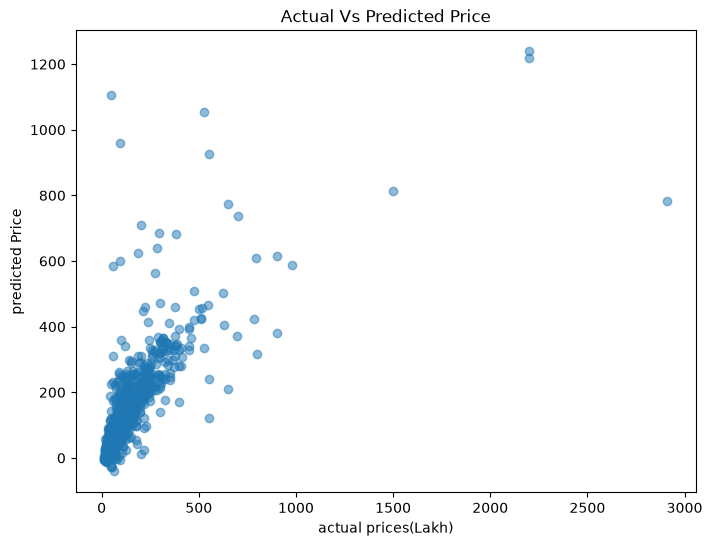

In [16]:
import matplotlib.pyplot as plt
plt.figure(figsize=(8,6))
plt.scatter(y_test,y_pred,alpha=0.5)

plt.title("Actual Vs Predicted Price")
plt.xlabel("actual prices(Lakh)")
plt.ylabel("predicted Price")
plt.show()

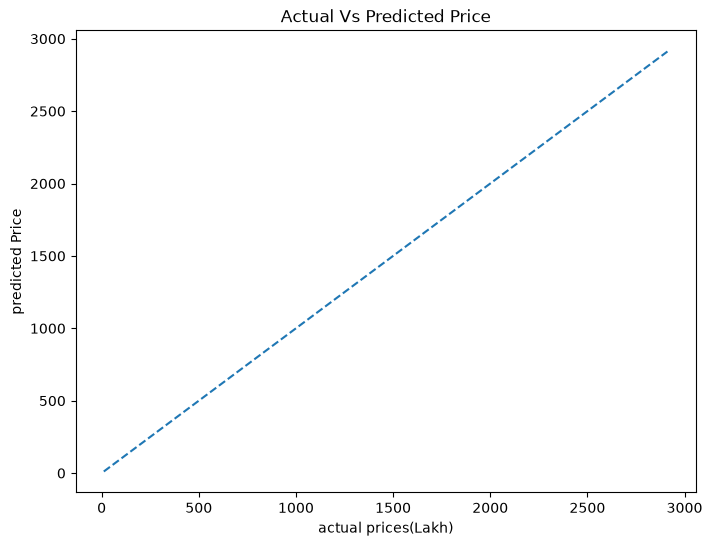

In [17]:
plt.figure(figsize=(8,6))
plt.plot(
    [y_test.min(),y_test.max()],
    [y_test.min(),y_test.max()],
    linestyle="--"
)
plt.title("Actual Vs Predicted Price")
plt.xlabel("actual prices(Lakh)")
plt.ylabel("predicted Price")
plt.show()


Actual values: 2135
Predicted values: 2135
First 5 predictions: [144.22747716  29.93250248 140.55631714 391.58671679  81.47101893]


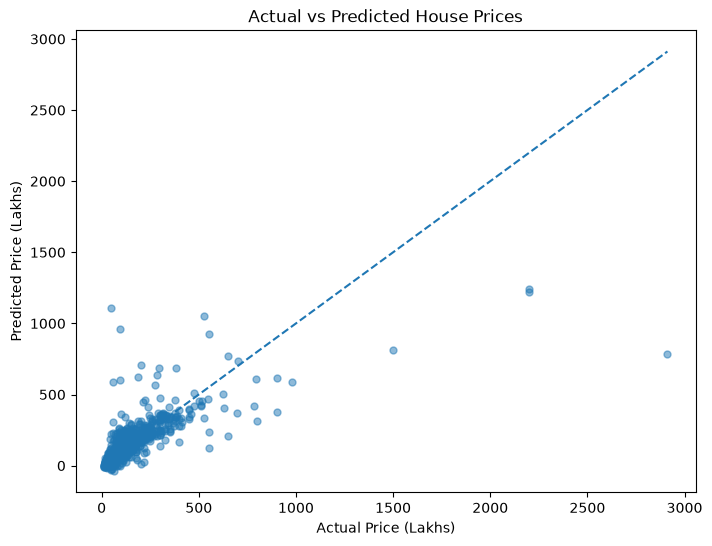

In [18]:


print("Actual values:", len(y_test))
print("Predicted values:", len(y_pred))
print("First 5 predictions:", y_pred[:5])

plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    y_pred,
    alpha=0.5,
    s=25
)

# Ideal prediction line
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)

plt.xlabel("Actual Price (Lakhs)")
plt.ylabel("Predicted Price (Lakhs)")
plt.title("Actual vs Predicted House Prices")

plt.show()

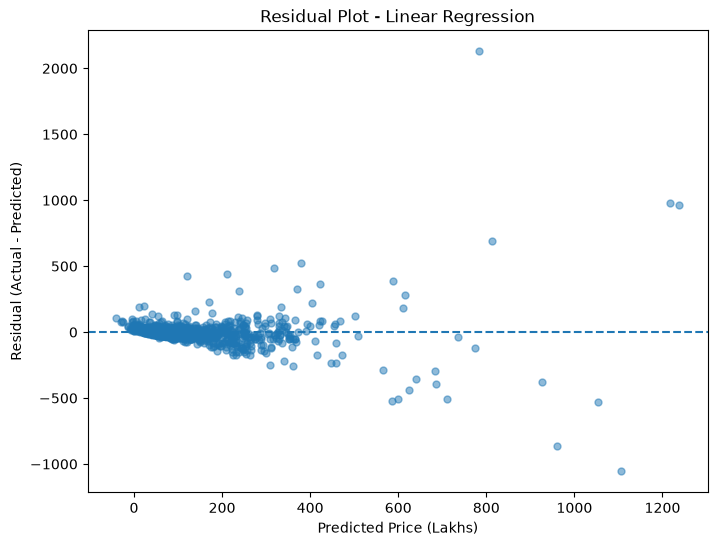

In [19]:
residuals = y_test - y_pred

plt.figure(figsize=(8, 6))

plt.scatter(
    y_pred,
    residuals,
    alpha=0.5,
    s=25
)

plt.axhline(0, linestyle="--")

plt.xlabel("Predicted Price (Lakhs)")
plt.ylabel("Residual (Actual - Predicted)")
plt.title("Residual Plot - Linear Regression")

plt.show()

In [20]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.pipeline import Pipeline

tree_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", DecisionTreeRegressor(
        random_state=42,
        max_depth=10
    ))
])

In [21]:
tree_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](6,)","['area_type','location','bhk','bath','total_sqft_num','balcony']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,6
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('categorical', ...), ('numerical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of co

In [22]:
tree_pred= tree_model.predict(X_test)
print(tree_pred[:10])

[148.40637931  47.55671733 148.40637931 355.49444444  54.71235695
  54.71235695  47.55671733 148.40637931  75.50348551  70.87082447]


In [23]:
from sklearn.metrics import mean_absolute_error, mean_squared_error,r2_score
import numpy as np

tree_mae=mean_absolute_error(y_test,tree_pred)

tree_rmse = np.sqrt(
    mean_squared_error(y_test, tree_pred)
)

tree_r2 = r2_score(y_test, tree_pred)

print("Decision Tree MAE:", tree_mae)
print("Decision Tree RMSE:", tree_rmse)
print("Decision Tree R²:", tree_r2)


Decision Tree MAE: 27.040314371609277
Decision Tree RMSE: 79.20389931088995
Decision Tree R²: 0.6259761785577165


In [29]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline

forest_model=Pipeline([
    ("preprocessor",preprocessor),
    ("model",RandomForestRegressor(
        n_estimators= 200,
        max_depth=15,
        random_state=42,
        n_jobs=-1
    ))
])

In [30]:
forest_model.fit(X_train, y_train)


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](6,)","['area_type','location','bhk','bath','total_sqft_num','balcony']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,6
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('categorical', ...), ('numerical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of co

In [33]:
forest_pred = forest_model.predict(X_test)
print(forest_pred[:10])

[146.78558881  46.58627455 151.80297532 361.81907876  56.50068321
  52.56907788  47.11752652 133.33170553  75.12512649  69.78978242]


In [34]:
forest_mae = mean_absolute_error(y_test, forest_pred)
forest_rmse = np.sqrt(mean_squared_error(y_test, forest_pred))
forest_r2 = r2_score(y_test, forest_pred)

print("Random Forest MAE:", forest_mae)
print("Random Forest RMSE:", forest_rmse)
print("Random Forest R²:", forest_r2)

Random Forest MAE: 24.599964556054935
Random Forest RMSE: 72.22224552406865
Random Forest R²: 0.68900879165042


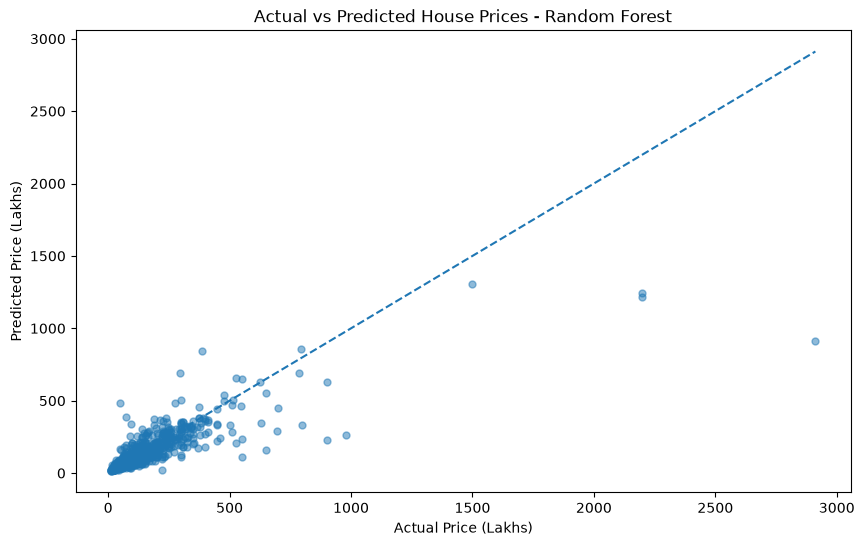

In [38]:
import matplotlib.pyplot as plt
plt.figure(figsize=(10,6))

plt.scatter(
    y_test,
    forest_pred,
    alpha=0.5,
    s=25
)
plt.plot(
    [y_test.min(),y_test.max()],
    [y_test.min(),y_test.max()],
    linestyle="--"
)

plt.xlabel("Actual Price (Lakhs)")
plt.ylabel("Predicted Price (Lakhs)")
plt.title("Actual vs Predicted House Prices - Random Forest")

plt.show()

In [39]:
forest_train_pred = forest_model.predict(X_train)

train_r2 = r2_score(y_train, forest_train_pred)
test_r2 = r2_score(y_test, forest_pred)

print("Training R²:", train_r2)
print("Testing R²:", test_r2)

Training R²: 0.8977160649284521
Testing R²: 0.68900879165042


In [40]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint

In [41]:
param_dist = {
    "model__n_estimators": randint(100, 400),
    "model__max_depth": randint(8, 25),
    "model__min_samples_split": randint(2, 15),
    "model__min_samples_leaf": randint(1, 8)
}

In [42]:
random_search = RandomizedSearchCV(
    estimator=forest_model,
    param_distributions=param_dist,
    n_iter=15,
    cv=3,
    scoring="neg_mean_absolute_error",
    random_state=42,
    n_jobs=-1
)

In [43]:
random_search.fit(X_train,y_train)

,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'model__max_depth': <scipy.stats....002CB68F5F610>, 'model__min_samples_leaf': <scipy.stats....002CB69216FD0>, 'model__min_samples_split': <scipy.stats....002CB6BB40690>, 'model__n_estimators': <scipy.stats....002CB6BB1EF90>}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",15
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'neg_mean_absolute_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",3
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``b

## 6. Hyperparameter Tuning Results (Random Forest)
Let's analyze the best hyperparameters found by `RandomizedSearchCV` and evaluate the tuned model on the unseen test set.

In [ ]:
# Retrieve best estimator and parameters
best_rf = random_search.best_estimator_
print("Best Random Forest Parameters:")
for param, val in random_search.best_params_.items():
    print(f"  {param}: {val}")

print(f"\nBest Cross-Validation MAE: {-random_search.best_score_:.4f} Lakhs")

# Evaluate on test set
best_rf_pred = best_rf.predict(X_test)
best_rf_mae = mean_absolute_error(y_test, best_rf_pred)
best_rf_rmse = np.sqrt(mean_squared_error(y_test, best_rf_pred))
best_rf_r2 = r2_score(y_test, best_rf_pred)

print(f"Tuned Random Forest Test R²: {best_rf_r2:.4f}")
print(f"Tuned Random Forest Test MAE: {best_rf_mae:.4f} Lakhs")
print(f"Tuned Random Forest Test RMSE: {best_rf_rmse:.4f} Lakhs")

## 7. Gradient Boosting Regressor
Gradient Boosting builds an ensemble of decision trees sequentially, each correcting the residual errors of prior trees. This often yields superior predictive power on complex tabular housing datasets.

In [ ]:
from sklearn.ensemble import GradientBoostingRegressor

gb_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", GradientBoostingRegressor(
        n_estimators=250,
        learning_rate=0.08,
        max_depth=5,
        subsample=0.85,
        random_state=42
    ))
])

gb_model.fit(X_train, y_train)

# Predict on Train and Test sets
gb_train_pred = gb_model.predict(X_train)
gb_test_pred = gb_model.predict(X_test)

gb_train_r2 = r2_score(y_train, gb_train_pred)
gb_r2 = r2_score(y_test, gb_test_pred)
gb_mae = mean_absolute_error(y_test, gb_test_pred)
gb_rmse = np.sqrt(mean_squared_error(y_test, gb_test_pred))

print(f"Gradient Boosting Train R²: {gb_train_r2:.4f}")
print(f"Gradient Boosting Test R²: {gb_r2:.4f}")
print(f"Gradient Boosting Test MAE: {gb_mae:.4f} Lakhs")
print(f"Gradient Boosting Test RMSE: {gb_rmse:.4f} Lakhs")

## 8. Regularized Baseline (Ridge Regression)
Let's train an L2-regularized linear model (Ridge) to test whether penalizing large coefficients improves linear generalization.

In [ ]:
from sklearn.linear_model import Ridge

ridge_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", Ridge(alpha=1.0))
])

ridge_model.fit(X_train, y_train)

ridge_train_pred = ridge_model.predict(X_train)
ridge_test_pred = ridge_model.predict(X_test)

ridge_train_r2 = r2_score(y_train, ridge_train_pred)
ridge_r2 = r2_score(y_test, ridge_test_pred)
ridge_mae = mean_absolute_error(y_test, ridge_test_pred)
ridge_rmse = np.sqrt(mean_squared_error(y_test, ridge_test_pred))

print(f"Ridge Regression Test R²: {ridge_r2:.4f}")
print(f"Ridge Regression Test MAE: {ridge_mae:.4f} Lakhs")
print(f"Ridge Regression Test RMSE: {ridge_rmse:.4f} Lakhs")

## 9. Comprehensive Model Comparison
Let's assemble a unified benchmark comparing all trained models across R², MAE, and RMSE on the held-out test dataset.

In [ ]:
# Summary comparison table
models_summary = pd.DataFrame([
    {
        "Model": "Gradient Boosting Regressor",
        "Train R²": round(gb_train_r2, 4),
        "Test R²": round(gb_r2, 4),
        "Test MAE (Lakhs)": round(gb_mae, 2),
        "Test RMSE (Lakhs)": round(gb_rmse, 2)
    },
    {
        "Model": "Tuned Random Forest",
        "Train R²": round(r2_score(y_train, best_rf.predict(X_train)), 4),
        "Test R²": round(best_rf_r2, 4),
        "Test MAE (Lakhs)": round(best_rf_mae, 2),
        "Test RMSE (Lakhs)": round(best_rf_rmse, 2)
    },
    {
        "Model": "Random Forest (Default)",
        "Train R²": round(train_r2, 4),
        "Test R²": round(forest_r2, 4),
        "Test MAE (Lakhs)": round(forest_mae, 2),
        "Test RMSE (Lakhs)": round(forest_rmse, 2)
    },
    {
        "Model": "Decision Tree (depth=10)",
        "Train R²": round(r2_score(y_train, tree_model.predict(X_train)), 4),
        "Test R²": round(tree_r2, 4),
        "Test MAE (Lakhs)": round(tree_mae, 2),
        "Test RMSE (Lakhs)": round(tree_rmse, 2)
    },
    {
        "Model": "Linear Regression",
        "Train R²": round(r2_score(y_train, linear_model.predict(X_train)), 4),
        "Test R²": round(r2, 4),
        "Test MAE (Lakhs)": round(mae, 2),
        "Test RMSE (Lakhs)": round(rmse, 2)
    },
    {
        "Model": "Ridge Regression",
        "Train R²": round(ridge_train_r2, 4),
        "Test R²": round(ridge_r2, 4),
        "Test MAE (Lakhs)": round(ridge_mae, 2),
        "Test RMSE (Lakhs)": round(ridge_rmse, 2)
    }
]).sort_values(by="Test R²", ascending=False).reset_index(drop=True)

models_summary

In [ ]:
# Visualizing model metrics comparison
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Plot R² Scores
bars1 = axes[0].barh(models_summary["Model"], models_summary["Test R²"], color="#3B82F6", edgecolor="#1E3A8A")
axes[0].set_xlabel("Test R² Score (Higher is better)")
axes[0].set_title("Model Comparison: Test R² Score", fontsize=12, fontweight="bold")
axes[0].set_xlim(0, 1.0)
axes[0].grid(axis="x", linestyle="--", alpha=0.6)
for bar in bars1:
    width = bar.get_width()
    axes[0].text(width + 0.015, bar.get_y() + bar.get_height()/2, f"{width:.3f}", va="center", fontweight="bold")

# Plot MAE
bars2 = axes[1].barh(models_summary["Model"], models_summary["Test MAE (Lakhs)"], color="#F97316", edgecolor="#C2410C")
axes[1].set_xlabel("Test MAE in Lakhs (Lower is better)")
axes[1].set_title("Model Comparison: Mean Absolute Error", fontsize=12, fontweight="bold")
axes[1].grid(axis="x", linestyle="--", alpha=0.6)
for bar in bars2:
    width = bar.get_width()
    axes[1].text(width + 0.5, bar.get_y() + bar.get_height()/2, f"₹{width:.1f}L", va="center", fontweight="bold")

plt.tight_layout()
plt.show()

## 10. Feature Importance Analysis
Let's inspect which features drive the model's price predictions most heavily.

In [ ]:
# Extract feature names from OneHotEncoder and numerical features
ohe = gb_model.named_steps["preprocessor"].named_transformers_["categorical"]
cat_names = list(ohe.get_feature_names_out(categorical_features))
all_feature_names = cat_names + numerical_features

importances = gb_model.named_steps["model"].feature_importances_
feat_df = pd.DataFrame({
    "Feature": all_feature_names,
    "Importance": importances
}).sort_values(by="Importance", ascending=False).reset_index(drop=True)

# Plot Top 15 Features
plt.figure(figsize=(10, 6))
top_15 = feat_df.head(15).iloc[::-1]
plt.barh(top_15["Feature"], top_15["Importance"], color="#10B981", edgecolor="#047857")
plt.xlabel("Relative Importance")
plt.title("Top 15 Most Influential Features (Gradient Boosting)", fontsize=13, fontweight="bold")
plt.grid(axis="x", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

print("Top 10 Most Important Features:")
feat_df.head(10)

## 11. Error & Residual Analysis
Let's examine the residual error distribution to confirm that errors are centered symmetrically around zero without systematic bias.

In [ ]:
# Select the champion model
champion_model = gb_model if gb_r2 >= best_rf_r2 else best_rf
champion_name = "Gradient Boosting Regressor" if champion_model == gb_model else "Tuned Random Forest"
print(f"Selected Champion Model: {champion_name}")

champ_preds = champion_model.predict(X_test)
champ_residuals = y_test - champ_preds

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Residual Histogram
axes[0].hist(champ_residuals, bins=50, color="#8B5CF6", edgecolor="black", alpha=0.7)
axes[0].axvline(0, color="red", linestyle="--", linewidth=1.5)
axes[0].set_xlabel("Residual (Actual - Predicted) [Lakhs]")
axes[0].set_ylabel("Frequency")
axes[0].set_title(f"Residual Error Distribution ({champion_name})", fontweight="bold")
axes[0].grid(True, linestyle="--", alpha=0.4)

# Actual vs Predicted Scatter
axes[1].scatter(y_test, champ_preds, alpha=0.45, s=25, color="#06B6D4")
axes[1].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "r--", linewidth=1.5, label="Ideal Fit")
axes[1].set_xlabel("Actual Price (Lakhs)")
axes[1].set_ylabel("Predicted Price (Lakhs)")
axes[1].set_title(f"Actual vs Predicted Prices ({champion_name})", fontweight="bold")
axes[1].legend()
axes[1].grid(True, linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

## 12. Inference Demonstration
Let's write a reusable inference function that takes typical property parameters and outputs formatted Indian Rupee valuations.

In [ ]:
def predict_bangalore_price(location, total_sqft, bhk, bath, balcony=1, area_type="Super built-up  Area"):
    input_df = pd.DataFrame([{
        "area_type": area_type,
        "location": location,
        "bhk": float(bhk),
        "bath": float(bath),
        "total_sqft_num": float(total_sqft),
        "balcony": float(balcony)
    }])
    pred_lakhs = champion_model.predict(input_df)[0]
    price_inr = pred_lakhs * 100_000
    price_per_sqft = price_inr / total_sqft
    
    if pred_lakhs >= 100:
        formatted = f"₹ {pred_lakhs/100:.2f} Crore"
    else:
        formatted = f"₹ {pred_lakhs:.2f} Lakhs"
        
    print(f"📍 {location} | {bhk} BHK | {total_sqft} sqft | {bath} Bath | {area_type}")
    print(f"   ↳ Valuation: {formatted} (₹ {price_per_sqft:,.0f} / sqft)\n")
    return pred_lakhs

# Test across popular Bangalore neighborhoods
print("=== Sample Bangalore Property Valuations ===\n")
p1 = predict_bangalore_price("Whitefield", total_sqft=1200, bhk=2, bath=2, balcony=1)
p2 = predict_bangalore_price("Indira Nagar", total_sqft=2000, bhk=3, bath=3, balcony=2)
p3 = predict_bangalore_price("Electronic City", total_sqft=850, bhk=2, bath=1, balcony=1)
p4 = predict_bangalore_price("HSR Layout", total_sqft=1500, bhk=3, bath=2, balcony=2)
p5 = predict_bangalore_price("Rajaji Nagar", total_sqft=1800, bhk=3, bath=3, balcony=2)

## 13. Export Champion Model & Artifacts
Finally, let's persist the champion model pipeline to `models/` along with JSON metadata containing unique localities, area types, and performance metrics for the Streamlit web application.

In [ ]:
import joblib
import json

# Ensure models directory exists
os.makedirs("../models", exist_ok=True)

# 1. Export winning pipeline
model_save_path = "../models/bangalore_house_price_model.joblib"
joblib.dump(champion_model, model_save_path)
print(f"✅ Successfully saved Champion Model to: {model_save_path}")

# 2. Export metadata
unique_locations = sorted([str(loc) for loc in df_model["location"].dropna().unique()])
unique_areas = sorted([str(area) for area in df_model["area_type"].dropna().unique()])

metadata = {
    "champion_model": champion_name,
    "features": features,
    "categorical_features": categorical_features,
    "numerical_features": numerical_features,
    "locations": unique_locations,
    "area_types": unique_areas,
    "total_locations_count": len(unique_locations),
    "metrics": {
        "test_r2": round(float(r2_score(y_test, champ_preds)), 4),
        "test_mae_lakhs": round(float(mean_absolute_error(y_test, champ_preds)), 2),
        "test_rmse_lakhs": round(float(np.sqrt(mean_squared_error(y_test, champ_preds))), 2)
    },
    "comparison_table": models_summary.to_dict(orient="records")
}

meta_save_path = "../models/metadata.json"
with open(meta_save_path, "w", encoding="utf-8") as f:
    json.dump(metadata, f, indent=4)
print(f"✅ Successfully saved metadata to: {meta_save_path} ({len(unique_locations)} locations, {len(unique_areas)} area types)")